In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
orders = pd.read_csv("olist_orders_dataset.csv")
order_items = pd.read_csv("olist_order_items_dataset.csv")
order_reviews = pd.read_csv("olist_order_reviews_dataset.csv")
products = pd.read_csv("olist_products_dataset.csv")
customers = pd.read_csv("olist_customers_dataset.csv")
sellers = pd.read_csv("olist_sellers_dataset.csv")
geo = pd.read_csv("olist_geolocation_dataset.csv")
payments = pd.read_csv("olist_order_payments_dataset.csv")

# Convertir las columnas de fechas de orders

orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

orders["order_estimated_delivery_date"] = pd.to_datetime(
    orders["order_estimated_delivery_date"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

## 1.Categoría de productos

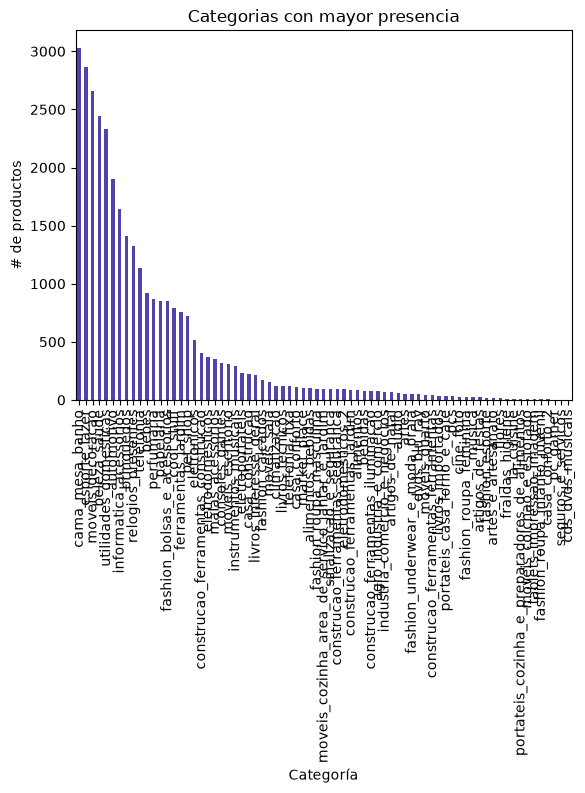

In [3]:
numero_de_productos = products["product_category_name"].value_counts()
ax1 = numero_de_productos.plot(kind="bar",
                title = "Categorias con mayor presencia",
                xlabel = "Categoría",
                ylabel = "# de productos",
                rot = 90,
                color = "#5242ac")
plt.show()

Los que tienen mayor presencia: `cama_mesa_banho`, `esporte_lazer`, `moveis_decorocao`, `beleza_saude`, `utilidades_domesticas`

## 2.Las categorías principales 

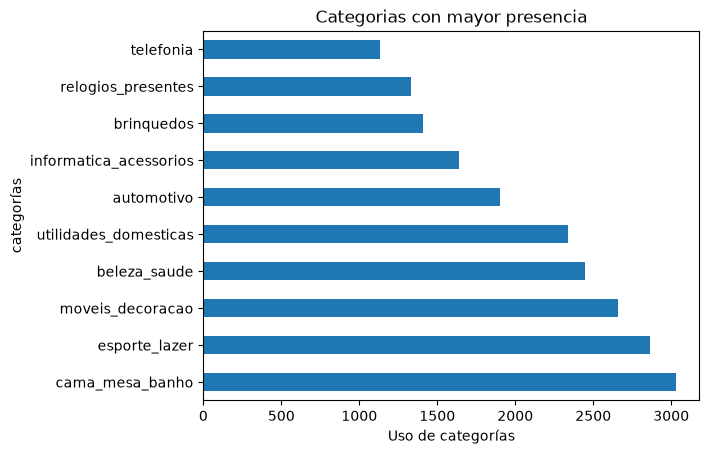

In [4]:
ax1 = numero_de_productos.head(10).plot(kind="barh",
                title = "Categorias con mayor presencia",
                rot = 0,
                xlabel = "Uso de categorías",
                ylabel = "categorías")
plt.show()

Los que tienen mayor presencia: `cama_mesa_banho`, `esporte_lazer`, `moveis_decorocao`, `beleza_saude`, `utilidades_domesticas` 

## 3.Distribución de productos

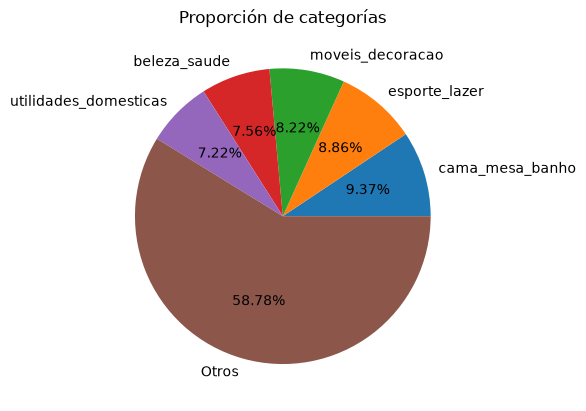

In [5]:
numero_de_productos = products["product_category_name"].value_counts().head(5)
numero_de_productos["Otros"] = products["product_category_name"].value_counts().iloc[5:].sum()
ax2 = numero_de_productos.plot(kind = "pie",
                            autopct="%1.2f%%",
                            color = "",
                            title = "Proporción de categorías",
                            ylabel = "")
plt.show()

Las 5 categorías principales están en el 41%, ninguna sobrepasa el 9.5% y el 58.78% se reparte entre todas las categorías.

## 4.Clientes por estado

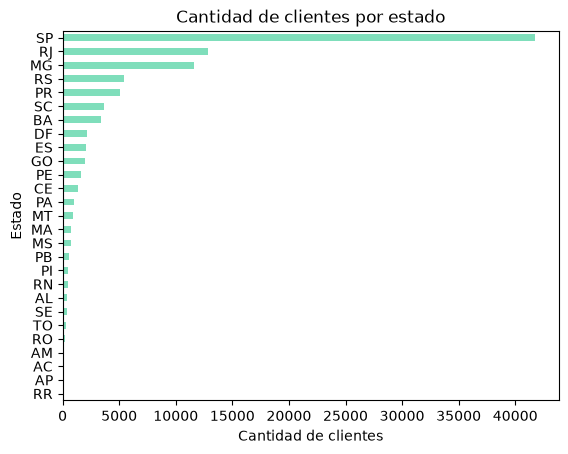

In [6]:
cantidad_de_clientes = customers["customer_state"].value_counts().sort_values(ascending= True)
ax3 = cantidad_de_clientes.plot(kind="barh",
                             title = "Cantidad de clientes por estado",
                             color = "#7fdebb",
                             xlabel="Cantidad de clientes",
                             ylabel= "Estado")
plt.show()

los más conccentrados son SP, RJ y MG

## 5.Estados principales

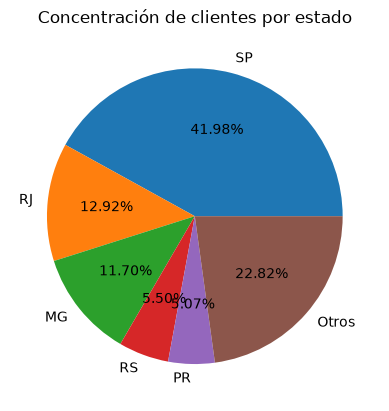

In [7]:
cantidad_de_clientes2 = customers["customer_state"].value_counts()
top5 = cantidad_de_clientes2.head(5)
top5["Otros"] = cantidad_de_clientes2.iloc[5:].sum()
ax5 = top5.plot(kind="pie",
                autopct = "%1.2f%%",
                title = "Concentración de clientes por estado",
                ylabel = "")

La mayor concentración es en SP 41.98%, RJ 12.92% Y MG 11.70%

## 6.Métodos de pago 

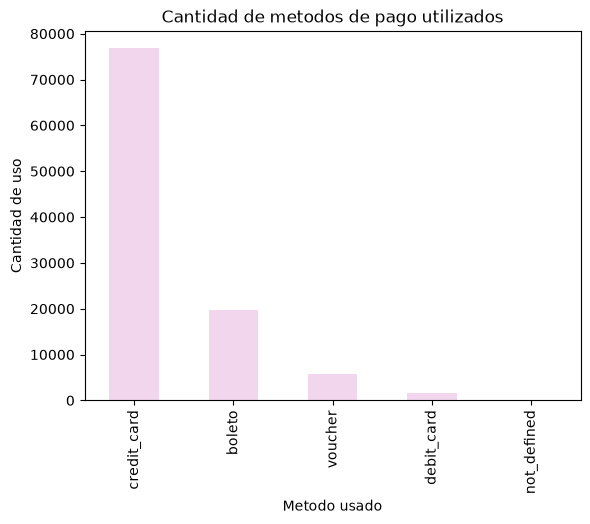

In [8]:
metodo_de_pago = payments["payment_type"].value_counts()
ax6 = metodo_de_pago.plot(kind="bar",
                          title= "Cantidad de metodos de pago utilizados",
                          color = "#efcbe8c5",
                          ylabel = "Cantidad de uso",
                          xlabel = "Metodo usado")
plt.show()

Método de pago más utilizado tarjeta de credito 

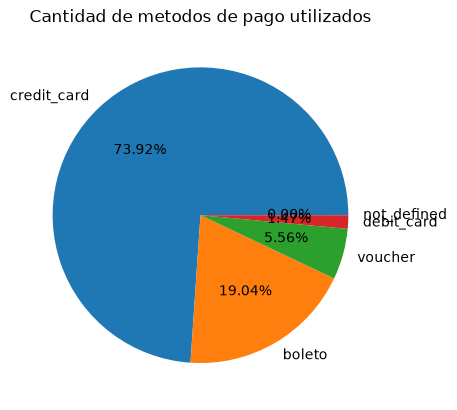

In [9]:
ax6_1 = metodo_de_pago.plot(kind = "pie",
                            title = "Cantidad de metodos de pago utilizados",
                            autopct = "%1.2f%%",
                            ylabel = "")
plt.show()

#### ¿Cuál de las dos gráficas permite comparar mejor los métodos de pago?
La gráfica de barras ayuda a comparar mejor los métodos de pago más cuando la cantidad es pequeña
#### ¿Cuál utilizarías si quisieras enfatizar la proporción que representa cada método?
 utilizaría la gráfica de pastel porque es más fácil mostrar la parte total de pagos

## 7.Número de cuotas 

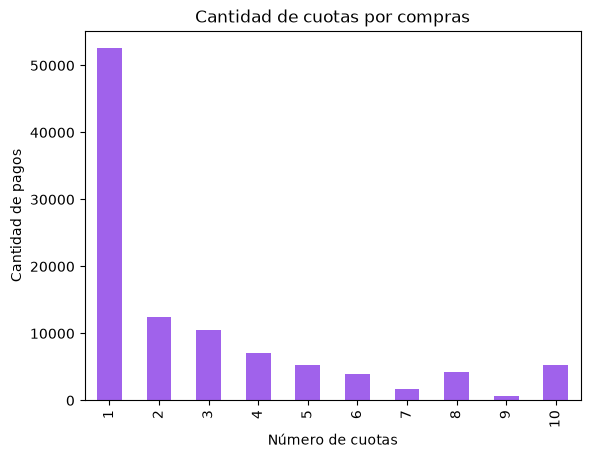

In [10]:
cantidad_cuotas = payments["payment_installments"].value_counts().sort_index().iloc[1:11]
ax6 = cantidad_cuotas.plot(kind="bar",
                             title = "Cantidad de cuotas por compras",
                             color = "#a062eb",
                             xlabel="Número de cuotas",
                             ylabel= "Cantidad de pagos")
plt.show()


La cuota uno es la más frecuentada

## 8. Comparando visualizaciones

In [11]:
payments.columns

Index(['order_id', 'payment_sequential', 'payment_type',
       'payment_installments', 'payment_value'],
      dtype='str')

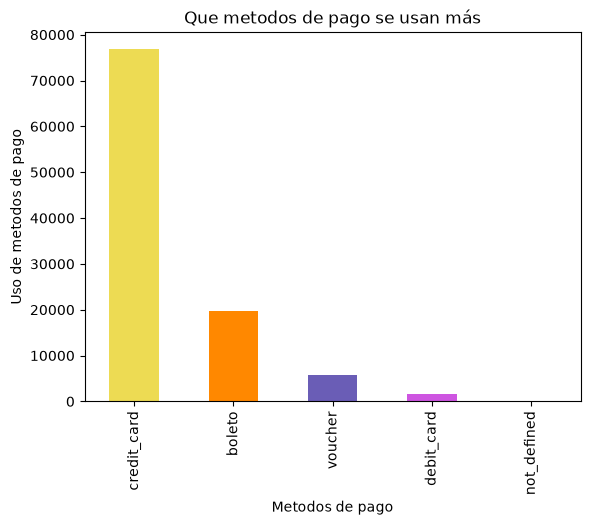

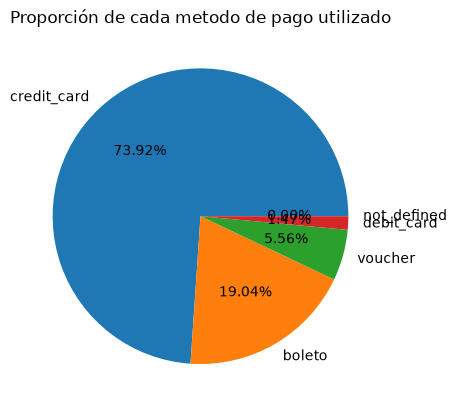

In [12]:
comparacion = payments["payment_type"].value_counts()
ax7 = comparacion.plot(kind= "bar",
                       color =[ "#eddb53","#ff8800","#6a5db6","#ce55e1"])
ax7.set_title("Que metodos de pago se usan más")
ax7.set_xlabel("Metodos de pago")
ax7.set_ylabel("Uso de metodos de pago")
plt.show()
ax7_2 = comparacion.plot(kind = "pie",
                        color = "",
                        autopct = "%1.2f%%")
ax7_2.set_title("Proporción de cada metodo de pago utilizado")
ax7_2.set_ylabel("")
plt.show()

### Pregunta 1
 Para comparar utilizaría gráfica de barras porque es más fácil visualizar que tan alto o bajo es una barra
### Pregunta 2
 Por proporciones es más facil la gráfica de pastel porque ahí hay un 100% y en el pastel ese 100% se reparte dependiendo del porcentaje y es más facil de entender cuando se trata de porcentajes 